# Öğrenme Oranı Programlarının Model Genellemesine Etkisi: Döngüsel ve Isınma Stratejileri
**Veri seti:** UCI Letter Recognition · **Model:** 16-256-256-26 MLP · **Optimizör:** SGD (momentum 0,9)

Bu not defteri çalışmanın tüm adımlarını sırasıyla gösterir: veri yükleme ve keşifsel analiz, öğrenme oranı programlarının tanımı, kısa bir eğitim gösterimi, kayıtlı deney sonuçlarının yüklenmesi, ve istatistiksel test. Tam deneyler `python src/run_experiments.py` ile yeniden üretilir (331 koşu, tek GPU'da ≈ 30 dakika).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import (load_dataframe, load_splits, make_schedule, SCHEDULES, SCHEDULE_LABELS, Config, train_run, SEEDS)
print('Seed listesi:', SEEDS)

Seed listesi: [42, 43, 44, 45, 46]


## 1. Veri seti ve keşifsel analiz 

In [2]:
df = load_dataframe()
print(df.shape, '| eksik değer:', int(df.isna().sum().sum()), '| yinelenen satır:', int(df.duplicated().sum()))
df.describe().T.round(2)

(20000, 17) | eksik değer: 0 | yinelenen satır: 1332


,count,mean,std,min,25%,50%,75%,max
x-box,20000.0,4.02,1.91,0.0,3.0,4.0,5.0,15.0
y-box,20000.0,7.04,3.30,0.0,5.0,7.0,9.0,15.0
width,20000.0,5.12,2.01,0.0,4.0,5.0,6.0,15.0
high,20000.0,5.37,2.26,0.0,4.0,6.0,7.0,15.0
onpix,20000.0,3.51,2.19,0.0,2.0,3.0,5.0,15.0
x-bar,20000.0,6.90,2.03,0.0,6.0,7.0,8.0,15.0
y-bar,20000.0,7.50,2.33,0.0,6.0,7.0,9.0,15.0
x2bar,20000.0,4.63,2.70,0.0,3.0,4.0,6.0,15.0
y2bar,20000.0,5.18,2.38,0.0,4.0,5.0,7.0,15.0
xybar,20000.0,8.28,2.49,0.0,7.0,8.0,10.0,15.0


In [3]:
sp = load_splits()
{k: v[0].shape for k, v in sp.items() if k in ('train', 'val', 'test')}

{'train': (14000, 16), 'val': (2000, 16), 'test': (4000, 16)}

## 2. Öğrenme oranı programları 
Tüm programlar iterasyon düzeyinde, açık formüllerle `src/common.py` içinde tanımlıdır.

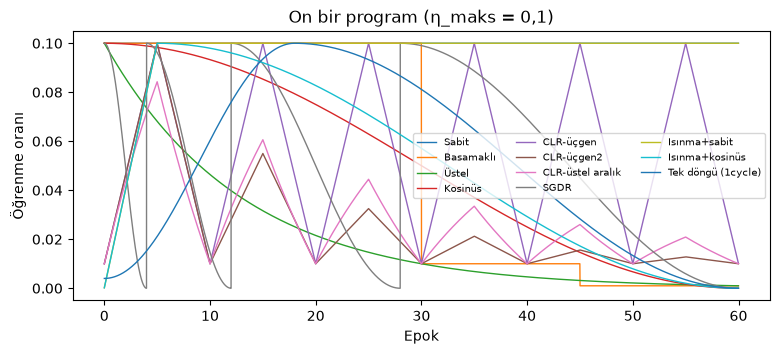

In [4]:
T, ipe = 6600, 110
fig, ax = plt.subplots(figsize=(9, 3.5))
for s in SCHEDULES:
    f = make_schedule(s, 0.1, T, ipe)
    ax.plot(np.arange(T) / ipe, [f(t) for t in range(T)], label=SCHEDULE_LABELS[s], lw=1)
ax.set_xlabel('Epok'); ax.set_ylabel('Öğrenme oranı'); ax.set_title('On bir program (η_maks = 0,1)')
ax.legend(ncol=3, fontsize=7); plt.show()

## 3. Kısa eğitim gösterimi
Tam deney 60 epoktur; burada gösterim amacıyla iki program 10 epok eğitilir.

In [5]:
for s in ['constant', 'cosine']:
    r = train_run(Config(schedule=s, epochs=10, seed=42), sp, keep_preds=False)
    f = r['final']
    print(f"{SCHEDULE_LABELS[s]:8s} test doğruluğu = {f['test_acc']*100:.2f}%  genelleme aralığı = {f['gap_acc']*100:.2f} puan")

Sabit    test doğruluğu = 95.03%  genelleme aralığı = 2.99 puan


Kosinüs  test doğruluğu = 95.62%  genelleme aralığı = 3.17 puan


## 4. Kayıtlı deney sonuçları 

In [6]:
pd.read_csv(ROOT / 'tables' / 'T6_ana_performans.csv')

,Program,Test doğruluğu (%),Makro-F1 (%),Eğitim doğruluğu (%),Genelleme aralığı (puan),Test kaybı,ECE (%),Keskinlik (×10⁻³),Δ sabit (puan),p (Holm)
0,Sabit,96.20 ± 0.24,96.19,98.92,2.72 ± 0.33,0.130,2.21,2.94,—,—
1,Basamaklı,97.04 ± 0.18,97.04,99.79,2.74 ± 0.18,0.105,2.59,2.15,+0.85,0.0344
2,Üstel,96.51 ± 0.09,96.51,99.62,3.10 ± 0.09,0.121,2.71,2.92,+0.32,0.0966
3,Kosinüs,96.96 ± 0.12,96.95,99.82,2.86 ± 0.12,0.109,2.70,2.48,+0.76,0.0344
4,CLR-üçgen,96.95 ± 0.18,96.94,99.80,2.85 ± 0.16,0.106,2.37,2.02,+0.75,0.0344
5,CLR-üçgen2,96.74 ± 0.07,96.73,99.71,2.97 ± 0.06,0.119,2.70,2.74,+0.54,0.0344
6,CLR-üstel aralık,96.71 ± 0.08,96.70,99.74,3.03 ± 0.06,0.118,2.72,2.76,+0.51,0.0434
7,SGDR,97.06 ± 0.13,97.05,99.80,2.74 ± 0.14,0.108,2.74,2.34,+0.87,0.0220
8,Isınma+sabit,96.21 ± 0.32,96.21,98.99,2.78 ± 0.23,0.128,2.16,2.59,+0.01,0.8674
9,Isınma+kosinüs,96.99 ± 0.14,96.99,99.82,2.83 ± 0.15,0.109,2.66,2.27,+0.80,0.0273


In [7]:
pd.read_csv(ROOT / 'tables' / 'T6b_lr_duyarlilik.csv')

,Program,η=0.01,η=0.025,η=0.05,η=0.1,η=0.2,η=0.4,Doğrulamayla seçilen η*,η*'da test (%)
0,Sabit,95.69 ± 0.08,96.39 ± 0.18,96.50 ± 0.09,96.14 ± 0.27,95.71 ± 0.72,91.55 ± 0.54,0.05,96.50 ± 0.09
1,Kosinüs,94.93 ± 0.24,96.02 ± 0.09,96.62 ± 0.14,96.93 ± 0.14,97.14 ± 0.08,97.26 ± 0.06,0.40,97.26 ± 0.06
2,CLR-üçgen2,93.05 ± 0.29,95.31 ± 0.04,96.08 ± 0.01,96.76 ± 0.08,96.88 ± 0.14,97.23 ± 0.10,0.40,97.23 ± 0.10
3,Isınma+kosinüs,94.95 ± 0.09,96.16 ± 0.06,96.66 ± 0.05,96.98 ± 0.18,97.08 ± 0.17,97.46 ± 0.10,0.40,97.46 ± 0.10
4,Tek döngü (1cycle),94.96 ± 0.08,96.13 ± 0.07,96.63 ± 0.13,96.94 ± 0.15,97.17 ± 0.07,97.38 ± 0.09,0.40,97.38 ± 0.09


In [8]:
pd.read_csv(ROOT / 'tables' / 'T7_ablasyon.csv')

,Ablasyon grubu,Ayar,Test doğruluğu (%),Genelleme aralığı (puan),Iraksayan koşu
0,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=0,96.93 ± 0.14,2.89 ± 0.14,0/3
1,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=1,96.88 ± 0.10,2.94 ± 0.11,0/3
2,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=3,97.05 ± 0.08,2.78 ± 0.07,0/3
3,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=5,96.98 ± 0.18,2.85 ± 0.18,0/3
4,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=10,97.03 ± 0.08,2.80 ± 0.05,0/3
5,"Isınma süresi (Isınma+kosinüs, η=0,1)",warmup_epochs=20,96.88 ± 0.06,2.95 ± 0.06,0/3
6,"Isınma süresi (Isınma+kosinüs, η=0,4)",warmup_epochs=0,97.26 ± 0.06,2.52 ± 0.08,0/3
7,"Isınma süresi (Isınma+kosinüs, η=0,4)",warmup_epochs=1,97.38 ± 0.13,2.46 ± 0.12,0/3
8,"Isınma süresi (Isınma+kosinüs, η=0,4)",warmup_epochs=3,97.26 ± 0.05,2.55 ± 0.02,0/3
9,"Isınma süresi (Isınma+kosinüs, η=0,4)",warmup_epochs=5,97.46 ± 0.10,2.39 ± 0.12,0/3


## 5. İstatistiksel test: eşleştirilmiş t testi + Holm düzeltmesi

In [9]:
from scipy import stats
main = json.load(open(ROOT / 'results' / 'main.json', encoding='utf-8'))
acc = lambda s: np.array([r['final']['test_acc'] for r in sorted([r for r in main if r['config']['schedule'] == s], key=lambda r: r['config']['seed'])]) * 100
base = acc('constant'); names = [s for s in SCHEDULES if s != 'constant']
raw = {s: stats.ttest_rel(acc(s), base).pvalue for s in names}
order = sorted(names, key=raw.get); holm, run = {}, 0
for i, s in enumerate(order):
    run = max(run, min(1, (len(order) - i) * raw[s])); holm[s] = run
pd.DataFrame({'program': [SCHEDULE_LABELS[s] for s in names], 'fark (puan)': [round(acc(s).mean() - base.mean(), 2) for s in names],
              'p (Holm)': [round(holm[s], 4) for s in names]})

,program,fark (puan),p (Holm)
0,Basamaklı,0.85,0.0344
1,Üstel,0.32,0.0966
2,Kosinüs,0.76,0.0344
3,CLR-üçgen,0.75,0.0344
4,CLR-üçgen2,0.54,0.0344
5,CLR-üstel aralık,0.51,0.0434
6,SGDR,0.87,0.0220
7,Isınma+sabit,0.01,0.8674
8,Isınma+kosinüs,0.80,0.0273
9,Tek döngü (1cycle),0.77,0.0344


## 6. Şekiller 

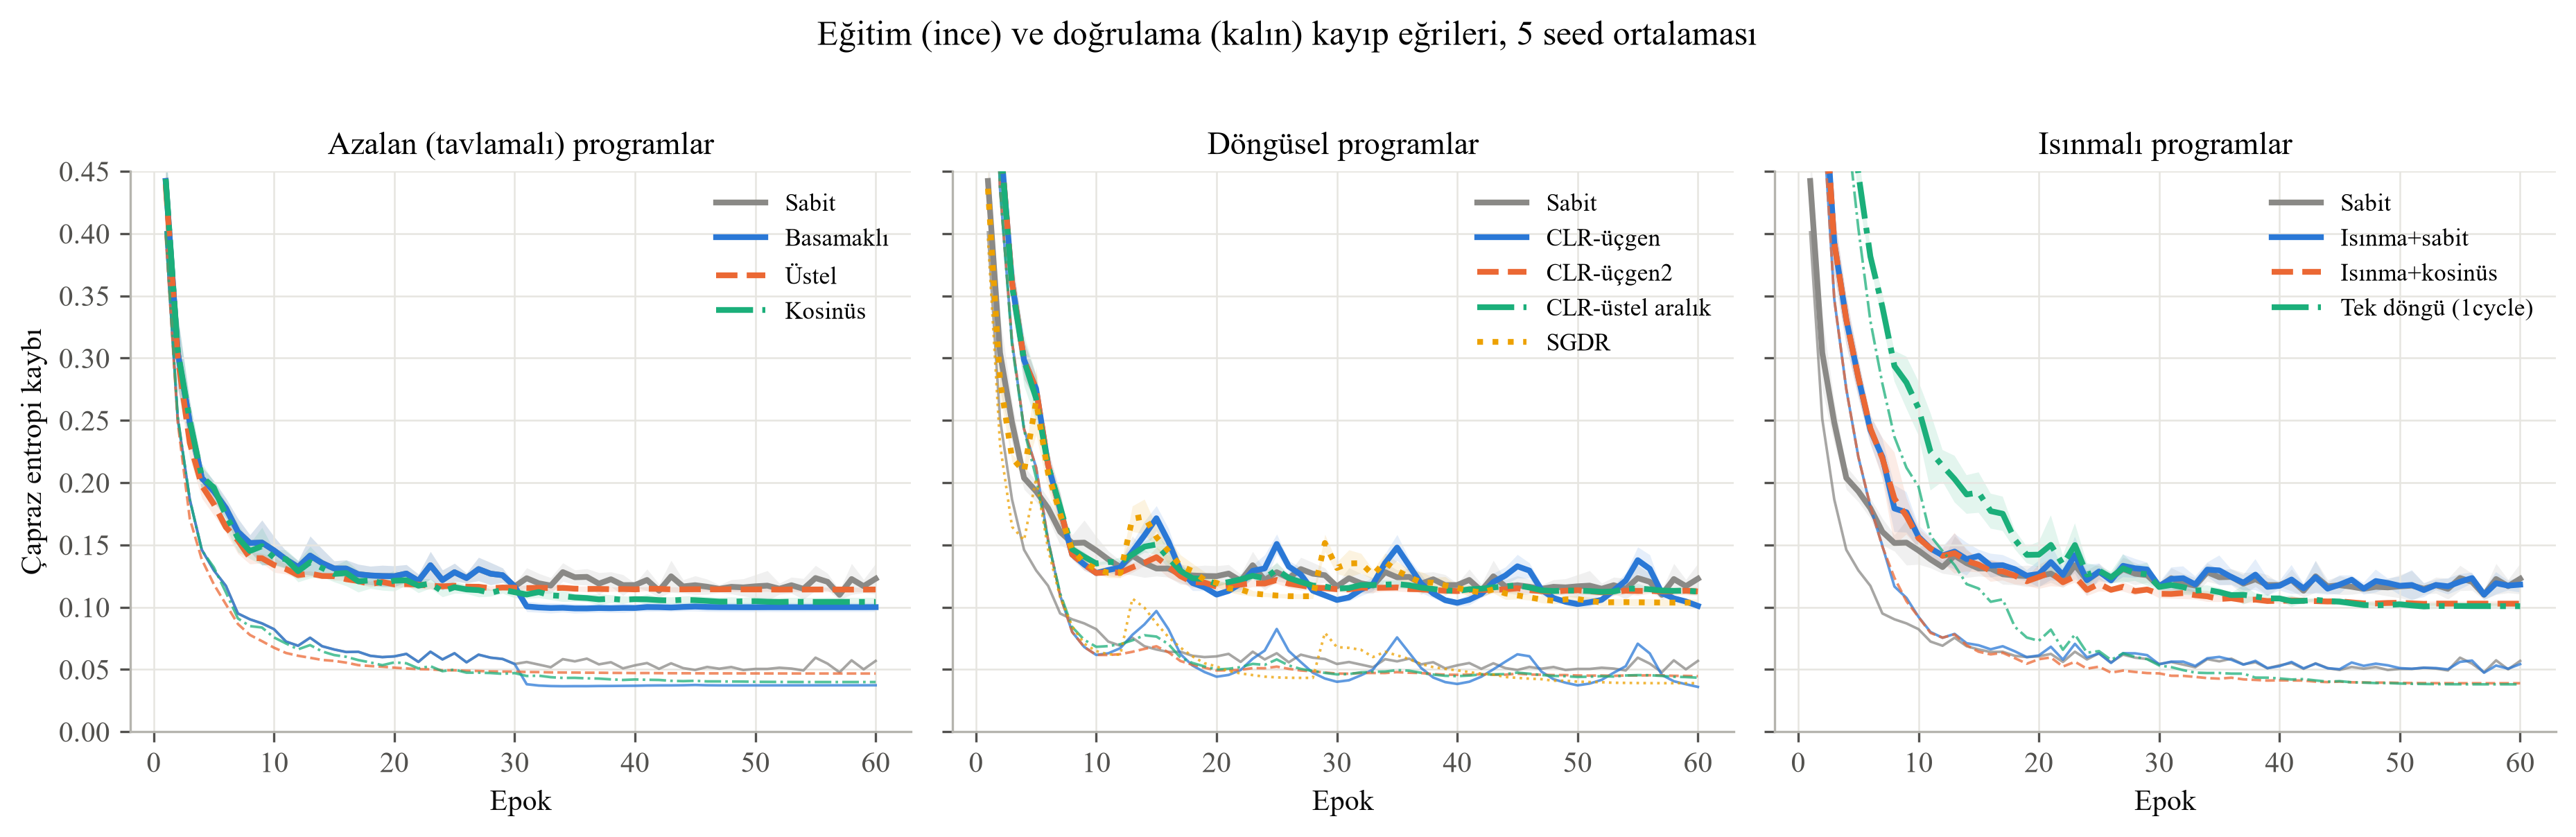

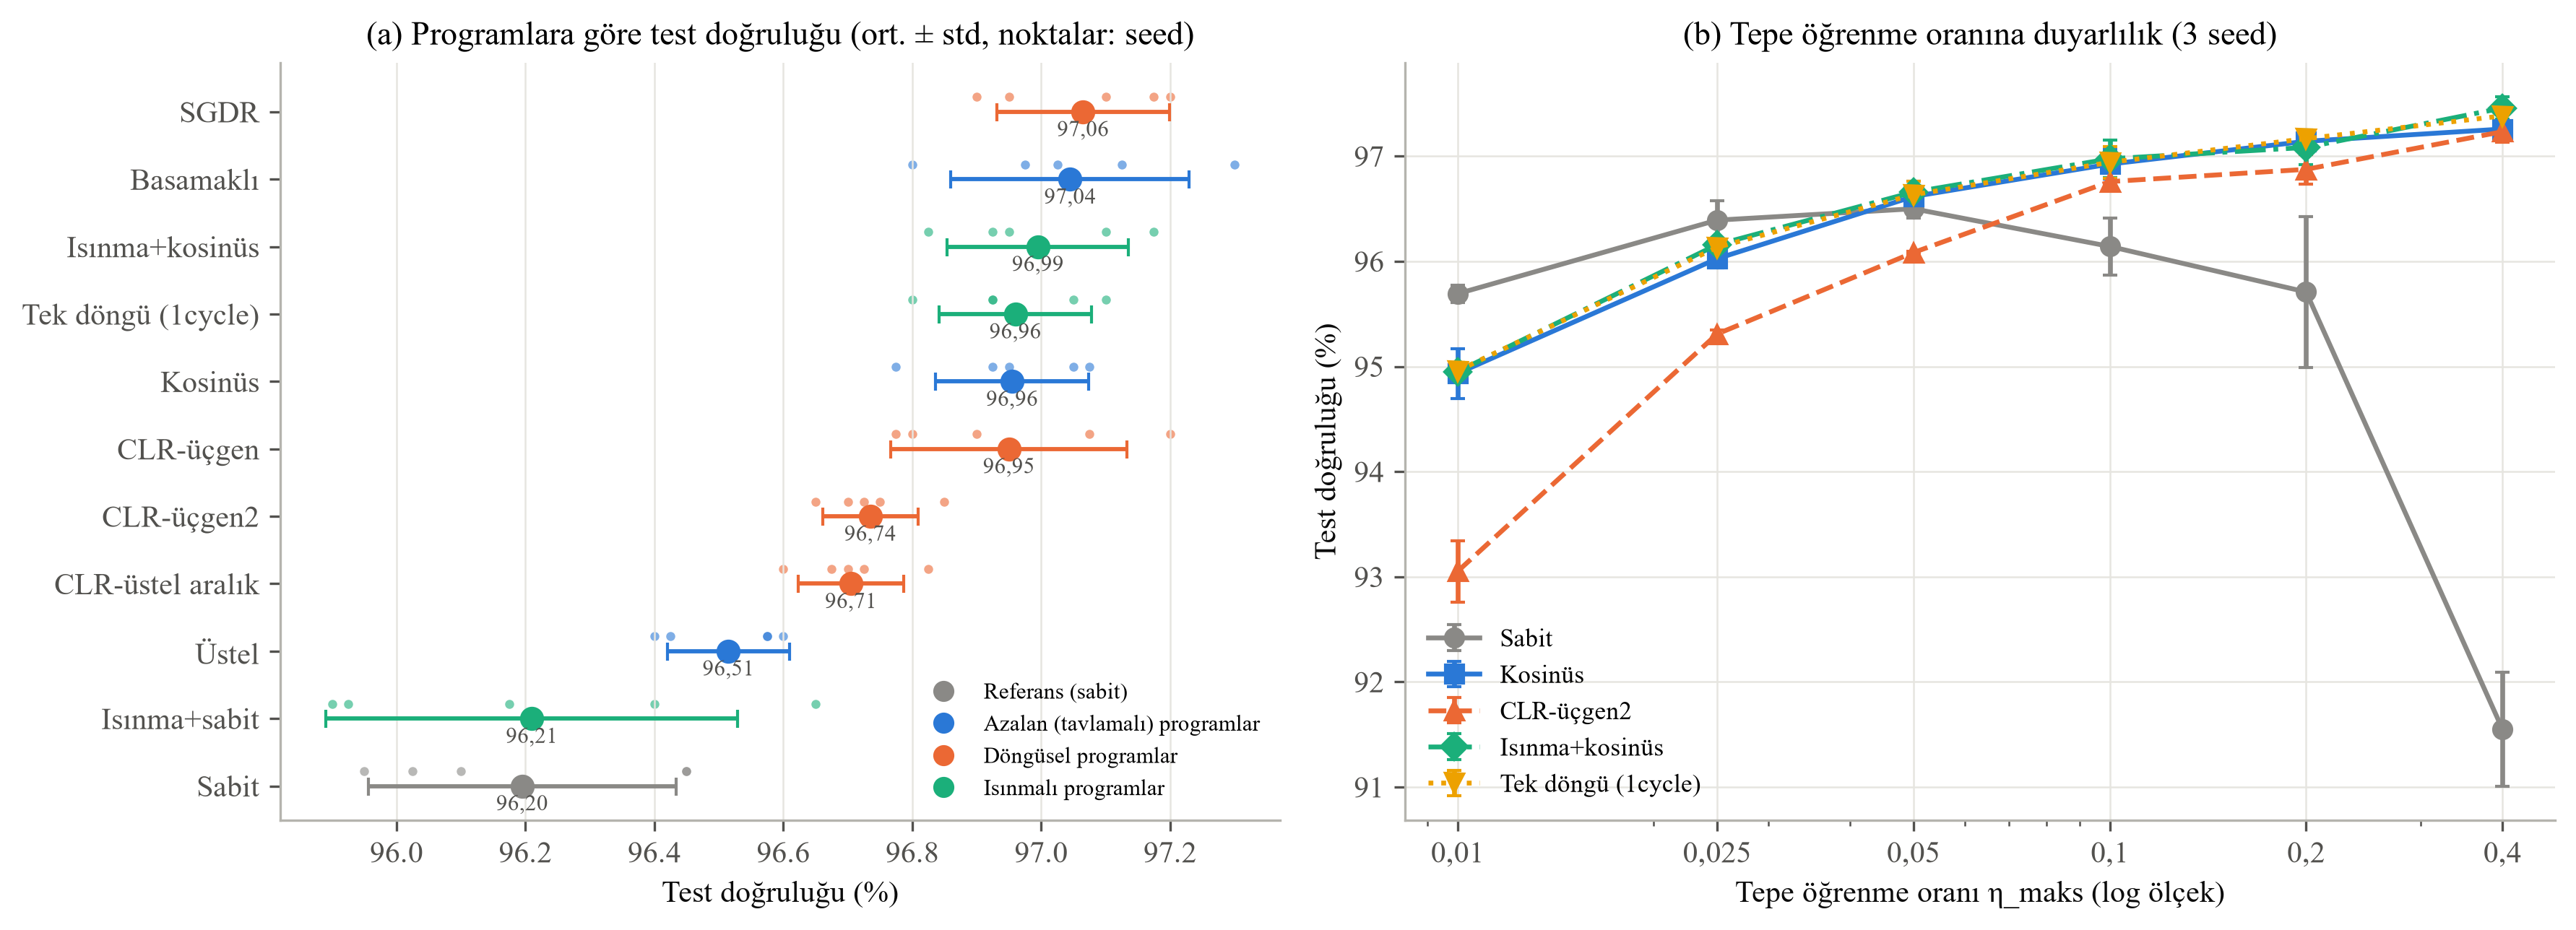

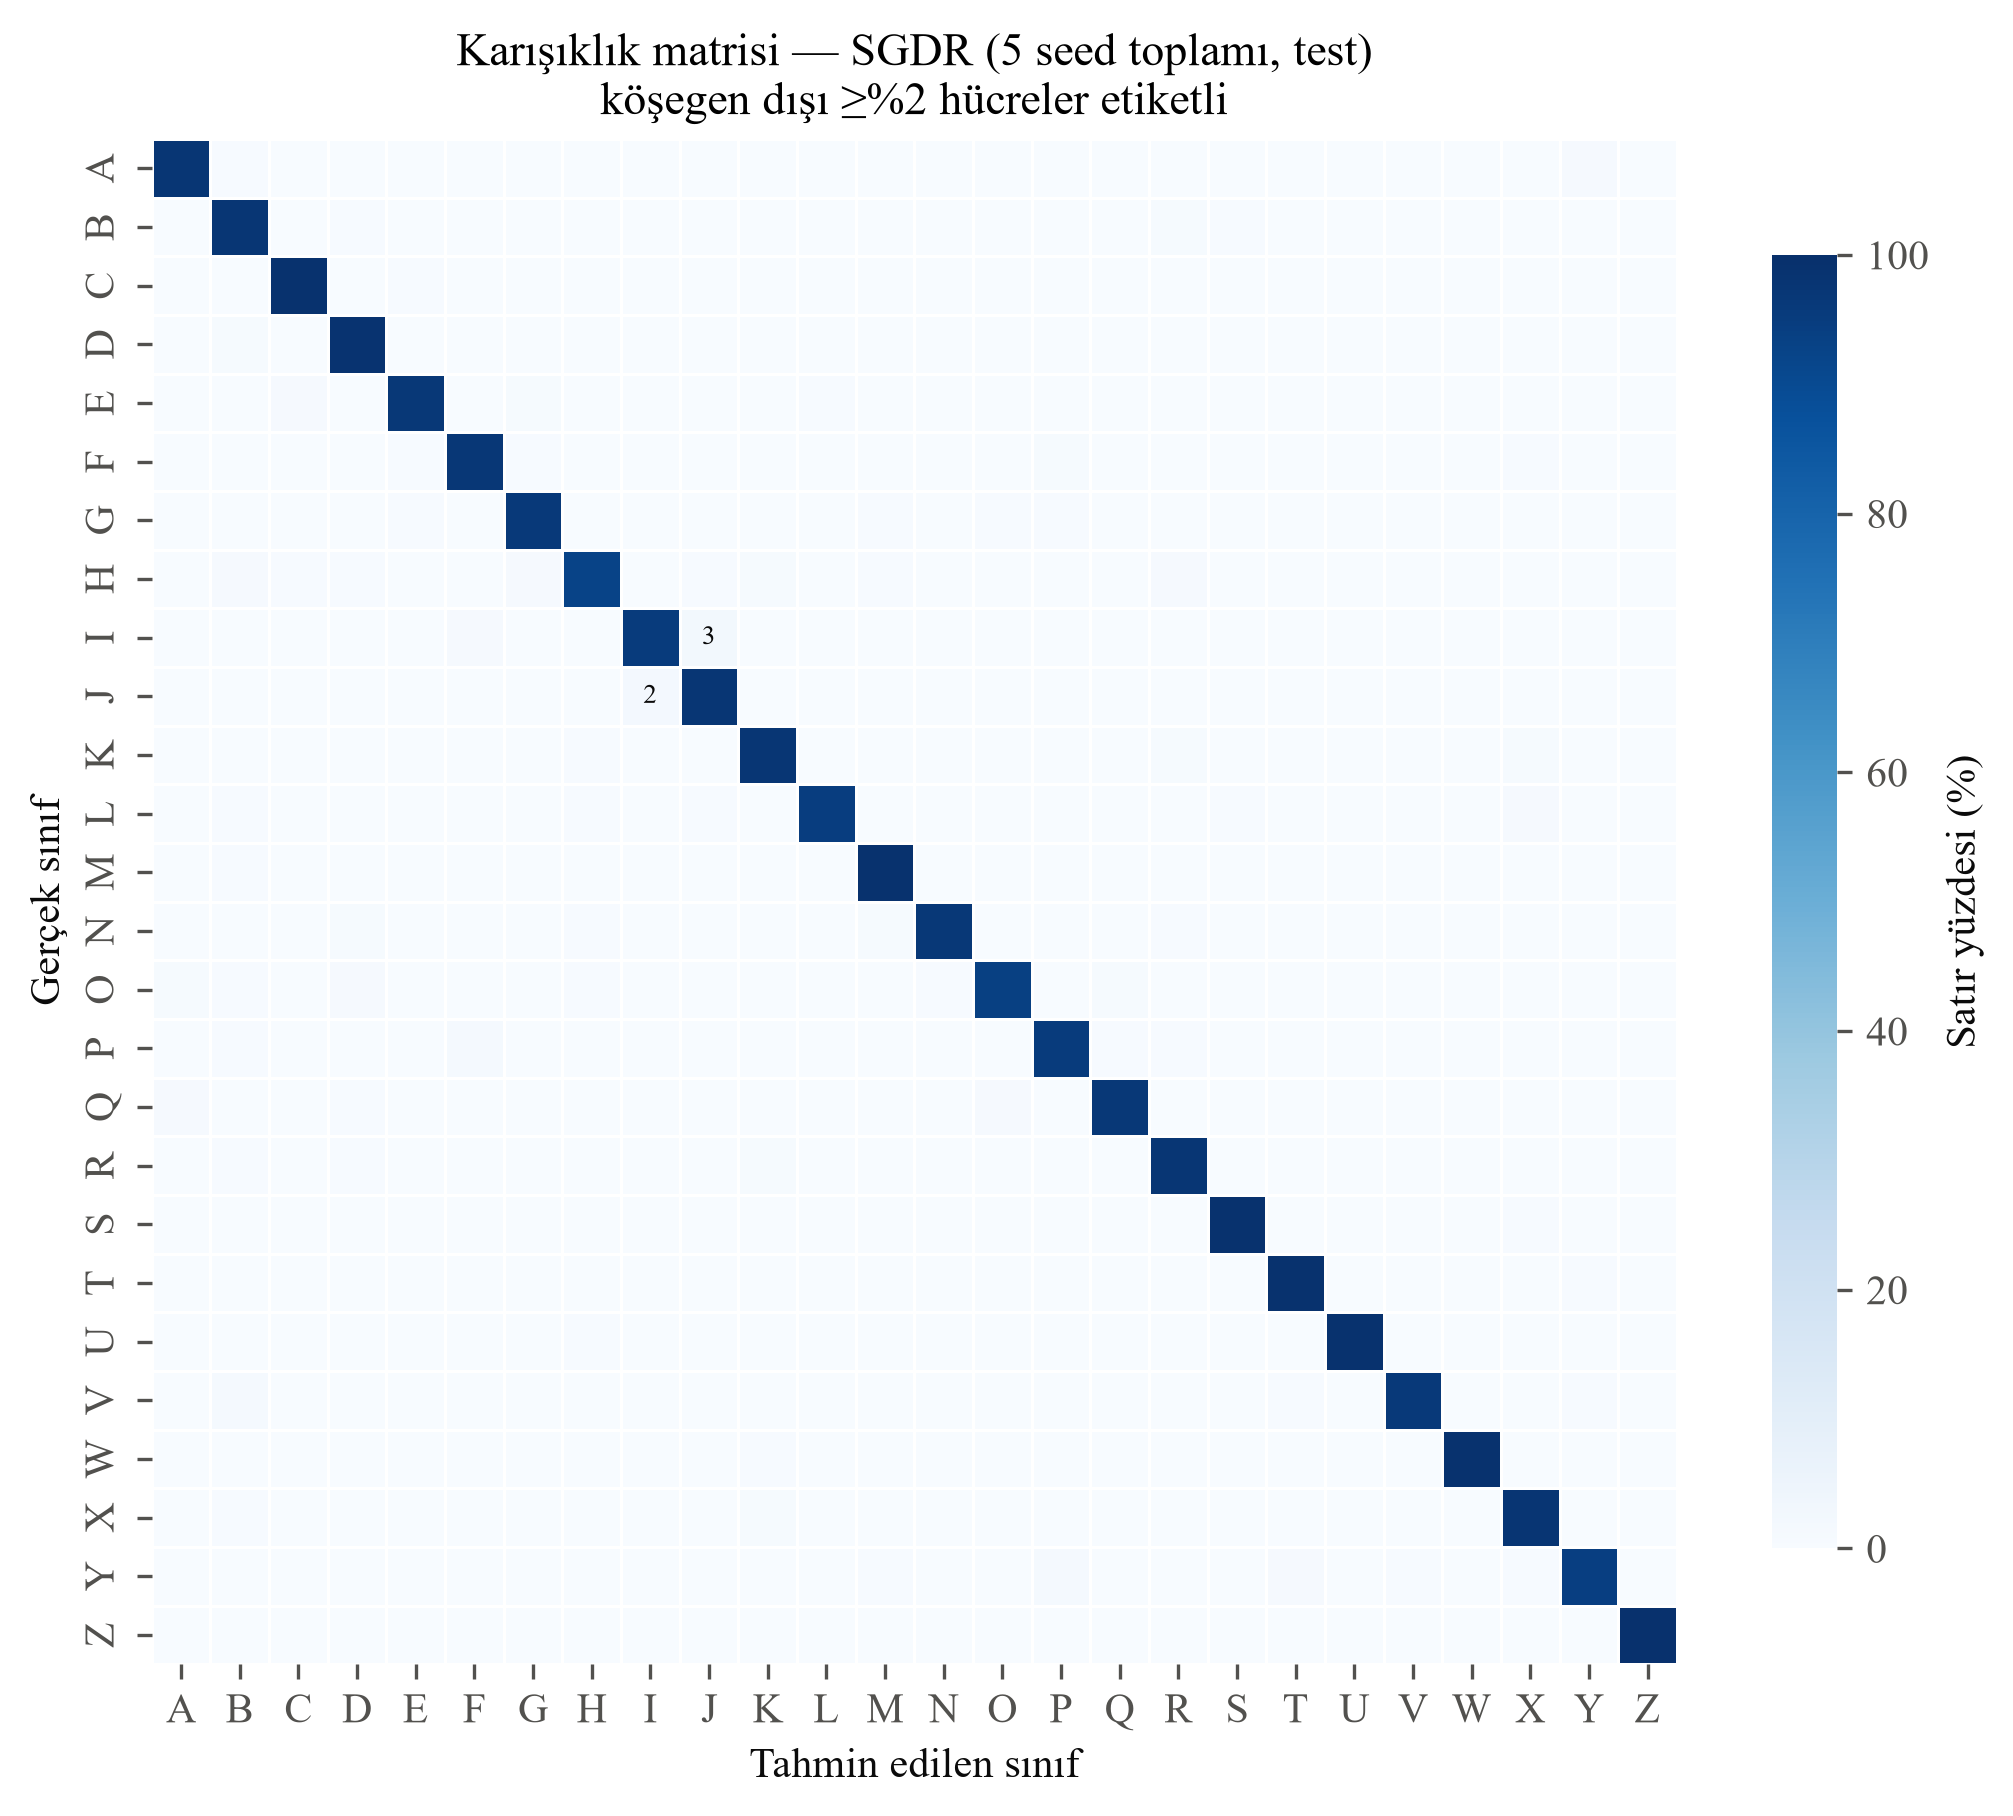

In [10]:
from IPython.display import Image, display
for g in ['G4_kayip_egrileri', 'G6_karsilastirmali_analiz', 'G7_karisiklik_matrisi']:
    display(Image(filename=str(ROOT / 'figures' / f'{g}.png'), width=800))